# 06. 후보 선정

4단계 결과를 근거로 2호점 후보를 좁힙니다.

| 순서 | 기준 | 근거 |
|---|---|---|
| ① 데이터 신뢰 | 최근 4개 분기(2025Q3~2026Q2) 모두 매출이 있고 결제부족이 아님 | 이슈 로그 9번 |
| ② 콘셉트 적합 | 오전·점심 비중, 주중 비중이 둘 다 서울 중앙값 이상 (4분기 평균) | 직장인 테이크아웃 콘셉트 |
| ③ 추세 | 최근 4분기 평균 점포당 매출이 그 전 4분기 평균보다 올라감 | H5 (상위권도 넷 중 하나는 밀려남) |
| ④ 경쟁 | 프랜차이즈 비중이 서울 중앙값보다 낮음 (4분기 평균) | 대형 프랜차이즈와 정면 경쟁 피하기 |
| ⑤ 순위 | 최근 4분기 평균 점포당 매출 상위 10곳 | H5 (순위가 잘 유지됨) |
| ⑥ 검토 | 10곳에 임대료, 직장인구, 역세권, 매장 하나 더 들어갈 때의 영향을 붙여 보고 3곳 선정 | H1, H3 |

폐업률은 표에 보여 주기만 하고 거르는 데는 쓰지 않습니다(H6 결과가 불안정).
①~⑤는 `sql/03_후보_선정.sql`에서 계산하고, 이 노트북에서는 결과를 확인하고 ⑥에 쓸 자료를 붙입니다.

처음에는 ③이 "줄지 않음"이었고 ④가 없었습니다. 그 기준으로 뽑은 상위 10곳을 보니 프랜차이즈 비중이 30~41%인 오피스 상권이 많았습니다(서울 중앙값 22%). 작은 브랜드가 대형 프랜차이즈와 정면으로 붙는 걸 피하자는 판단으로 ③을 "올라감"으로 바꾸고 ④를 넣었습니다. 명단을 본 뒤에 바꾼 기준이라 바꾼 이유를 결정 기록에 남겼습니다.

In [1]:
import os
import glob
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

load_dotenv('../.env')
url = URL.create(
    drivername='postgresql+psycopg2',
    username=os.environ['PGUSER'],
    password=os.environ['PGPASSWORD'],
    host=os.environ['PGHOST'],
    port=int(os.environ['PGPORT']),
    database=os.environ['PGDATABASE'],
)
engine = create_engine(url)

#### 코드 읽기
- `glob`, `unicodedata`: 임대료 CSV 파일을 찾을 때 씁니다. 01 노트북에서처럼 맥의 한글 파일 이름(NFD) 문제 때문에 이름을 NFC로 바꿔서 비교합니다.
- 나머지는 이전 노트북들과 같은 준비 과정입니다.

## 1. 후보 테이블 만들기 (①~⑤)

`sql/03_후보_선정.sql`은 04 노트북이 만든 `분석_대상` 뷰를 씁니다. 04를 먼저 돌려 둬야 합니다.

In [2]:
with open('../sql/03_후보_선정.sql', encoding='utf-8') as f:
    sql = f.read()

with engine.begin() as conn:
    for statement in sql.split(';'):
        if statement.strip():
            conn.execute(text(statement))

cand = pd.read_sql('SELECT * FROM 후보_지표', engine)
print(cand.shape)

(1058, 24)


#### 코드 읽기
- SQL 파일을 문장 단위로 실행해서 `후보_지표` 테이블을 만듭니다. 방식은 02, 04 노트북과 같습니다.
- `cand`: 2026년 2분기에 매출이 있는 상권마다 한 줄이고, 기준별 통과 여부(0/1)와 순위가 붙어 있습니다.

In [3]:
funnel = pd.DataFrame({
    '단계': ['2026Q2 매출 있는 상권', '① 데이터 신뢰', '② 콘셉트 적합', '③ 추세', '④ 경쟁', '⑤ 상위 10곳'],
    '남은_상권_수': [
        len(cand),
        cand['통과1_신뢰'].sum(),
        cand['통과2_콘셉트'].sum(),
        cand['통과3_추세'].sum(),
        cand['통과4_경쟁'].sum(),
        (cand['순위'] <= 10).sum(),
    ],
})
funnel

,단계,남은_상권_수
0,2026Q2 매출 있는 상권,1058
1,① 데이터 신뢰,974
2,② 콘셉트 적합,349
3,③ 추세,195
4,④ 경쟁,95
5,⑤ 상위 10곳,10


#### 코드 읽기
- `pd.DataFrame({...})`: 단계 이름 리스트와 상권 수 리스트로 표를 만듭니다. 두 리스트의 길이가 같아야 합니다.
- `cand['통과1_신뢰'].sum()`: 0/1 컬럼이라 더하면 통과한 상권 수입니다.
- `(cand['순위'] <= 10).sum()`: 순위가 없는(④까지 통과 못 한) 상권은 순위가 비어 있고, 빈 값은 비교하면 False가 돼서 자연스럽게 빠집니다.

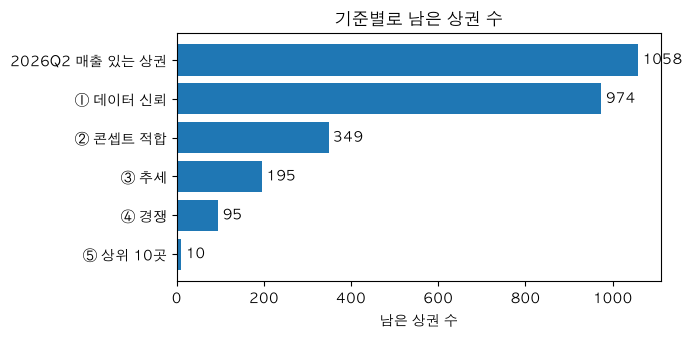

In [4]:
plt.figure(figsize=(7, 3.5))
plt.barh(funnel['단계'], funnel['남은_상권_수'])
plt.gca().invert_yaxis()
for i, n in enumerate(funnel['남은_상권_수']):
    plt.text(n + 10, i, str(n), va='center')
plt.xlabel('남은 상권 수')
plt.title('기준별로 남은 상권 수')
plt.tight_layout()
plt.show()

#### 코드 읽기
- `plt.barh(y, 길이)`: 가로 막대그래프입니다. 단계 이름이 길어서 세로 막대보다 읽기 편합니다.
- `plt.gca().invert_yaxis()`: `gca()`는 지금 그리고 있는 축을 가져옵니다. y축을 뒤집어서 첫 단계가 맨 위에 오게 합니다.
- `for i, n in enumerate(...)`: `enumerate`는 (순번, 값)을 같이 꺼내 줍니다. 막대 끝에서 조금 오른쪽(n + 10)에 숫자를 적습니다.
- `va='center'`: 글자를 막대 높이 가운데에 맞춥니다.

1,058곳이 ①에서 974곳, ②에서 349곳, ③에서 195곳으로 줄고 ④ 경쟁 기준을 지나 95곳이 남습니다. ②와 ④에서 가장 많이 걸러집니다. ④는 중앙값 기준이라 대략 절반이 남는데 실제로도 195곳 중 95곳이 남았습니다.

In [5]:
print('오전·점심 비중 중앙값:', round(cand['오전점심_중앙값'].iloc[0], 3))
print('주중 비중 중앙값    :', round(cand['주중_중앙값'].iloc[0], 3))
print('프랜차이즈 비중 중앙값:', round(cand['프랜차이즈_중앙값'].iloc[0], 3))

오전·점심 비중 중앙값: 0.498
주중 비중 중앙값    : 0.692
프랜차이즈 비중 중앙값: 0.218


#### 코드 읽기
- 중앙값은 모든 줄에 같은 값이 붙어 있어서(SQL의 `CROSS JOIN`) 첫 줄(`iloc[0]`) 값만 보면 됩니다.

중앙값은 오전·점심 49.8%, 주중 69.2%, 프랜차이즈 비중 21.8%입니다. 앞의 두 값은 2단계에서 본 2026년 2분기 값(50%, 69%)과 거의 같습니다.

## 2. 상위 10곳

In [6]:
top10 = cand[cand['순위'] <= 10].sort_values('순위').copy()

top10['점포당_매출_만원'] = (top10['최근_점포당_매출'] / 10000).round()
top10['추세_%'] = (top10['추세'] * 100).round(1)
top10['상권_매출_추세_%'] = (top10['상권_매출_추세'] * 100).round(1)

show_cols = ['순위', '상권_코드_명', '상권_유형', '자치구', '점포_수', '점포당_매출_만원', '추세_%', '상권_매출_추세_%',
             '오전점심_비중', '주중_비중', '프랜차이즈_비중', '직장인구', '지하철역_수', '폐업률']
top10[show_cols].round(3)

,순위,상권_코드_명,상권_유형,자치구,점포_수,점포당_매출_만원,추세_%,상권_매출_추세_%,오전점심_비중,주중_비중,프랜차이즈_비중,직장인구,지하철역_수,폐업률
192,1.0,성신여대입구역 4번,골목상권,성북구,10,15915.0,0.0,5.4,0.505,0.722,0.050,624.0,0.0,2.75
122,2.0,광나루역 1번,골목상권,광진구,9,14621.0,0.4,0.4,0.693,0.872,0.103,1004.0,1.0,5.25
717,3.0,을지로3가역,발달상권,중구,92,6861.0,5.1,3.9,0.586,0.836,0.187,13468.0,2.0,2.00
56,4.0,용산구청,골목상권,용산구,19,6078.0,9.2,2.6,0.525,0.702,0.120,6410.0,0.0,2.75
647,5.0,보인중학교,골목상권,송파구,7,5775.0,22.0,2.1,0.637,0.841,0.130,2429.0,0.0,7.25
884,6.0,강남구청역,발달상권,강남구,57,5595.0,10.7,8.7,0.603,0.838,0.171,15763.0,2.0,4.50
699,7.0,이화사거리,발달상권,종로구,22,5360.0,8.5,9.6,0.593,0.814,0.110,3008.0,0.0,2.25
209,8.0,종암중학교,골목상권,성북구,7,5285.0,15.5,15.5,0.516,0.847,0.000,1818.0,0.0,0.00
147,9.0,촬영소사거리,골목상권,동대문구,3,5023.0,7.1,7.1,0.882,1.000,0.000,760.0,0.0,0.00
851,10.0,서초역,발달상권,서초구,72,4982.0,1.2,5.3,0.687,0.734,0.216,15721.0,1.0,2.25


#### 코드 읽기
- `cand[cand['순위'] <= 10]`: 순위 10 이내만 남기고 순위대로 정렬합니다.
- `점포당_매출_만원`: 최근 4분기 평균 점포당 분기 매출을 만 원 단위로 바꿉니다.
- `추세_%`: 이전 4분기 대비 점포당 매출이 몇 % 변했는지입니다. SQL에서 `최근 ÷ 이전 − 1`로 계산해 뒀습니다.
- `상권_매출_추세_%`: 같은 방식으로 본 상권 전체 매출의 변화입니다. 거르는 데는 안 썼습니다. 점포가 문을 닫아서 점포당 매출만 버티는 상권(전체 매출은 줄어듦)을 알아보려고 같이 봅니다.
- `폐업률`: 최근 4분기 평균입니다. 거르는 데는 안 쓰고 보여 주기만 합니다.

상위 10곳은 여전히 두 갈래입니다.

- 성신여대입구역 4번, 광나루역 1번처럼 점포가 적고 직장인구가 1,000명 안팎인 골목상권이 절반 정도입니다.
- 을지로3가역, 강남구청역, 서초역은 직장인구가 1만 3천~1만 6천 명인 발달상권입니다.

처음 기준으로 뽑았던 시청역_8번, 삼성역, 서울역은 프랜차이즈 비중이 32~41%라서 ④에서 빠졌습니다. 그 대신 점포당 매출 수준이 낮아졌습니다. 처음 상위 10곳은 7,384만~3억 2,253만 원이었는데 이번에는 4,982만~1억 5,915만 원입니다. 대형 프랜차이즈를 피하는 대신 매출 규모를 일부 포기하는 셈입니다. 그래도 10곳 모두 서울 중앙값(1,483만 원)의 세 배가 넘습니다.

10곳 모두 상권 전체 매출도 늘었습니다(0.4~15.5%). 점포가 문을 닫아서 점포당 매출만 버티는 상권은 없습니다.

## 3. 검토 전에 확인할 것: 지하철역 수

처음 기준으로 뽑았던 상위 10곳의 시청역_8번, 을지로입구역처럼 이름에 역이 들어간 상권도 `지하철역_수`가 0이었습니다.
⑤에서 지하철역을 보기 전에 이 값이 무엇을 세는지 확인합니다.

In [7]:
latest = pd.read_sql('SELECT 상권_코드_명, 상권_유형, 지하철역_수 FROM 분석_대상 WHERE 기준_년분기_코드 = 20262', engine)

# 이름이 "OO역", "OO역 1번", "OO역_8번", "OO역(…)"처럼 역 이름으로 된 상권만
station_named = latest[latest['상권_코드_명'].str.contains(r'역(?:$|\s|_|\()')].copy()
station_named['역_0개'] = station_named['지하철역_수'] == 0

print('역 이름 상권:', len(station_named))
print('그중 지하철역_수가 0인 상권:', station_named['역_0개'].sum())
station_named.groupby('상권_유형')['역_0개'].mean().round(2)

역 이름 상권: 396
그중 지하철역_수가 0인 상권: 245


상권_유형
골목상권    0.85
발달상권    0.21
전통시장    1.00
Name: 역_0개, dtype: float64

#### 코드 읽기
- `str.contains(r'역(?:$|\s|_|\()')`: 정규표현식으로 이름에 "역" 다음에 문장 끝(`$`), 공백(`\s`), 밑줄(`_`), 여는 괄호(`\(`) 중 하나가 오는 상권을 찾습니다. 괄호 안 맨 앞의 `?:`는 "묶기만 하고 따로 꺼내지는 않는다"는 표시입니다. 이게 없으면 pandas가 꺼낼 부분이 있는 패턴이라며 경고를 띄웁니다. 그냥 "역"으로 찾으면 역삼동, 역촌동 같은 동네 이름까지 걸려서 이렇게 좁혔습니다. 앞의 `r`은 역슬래시를 글자 그대로 쓰겠다는 표시입니다.
- `station_named['역_0개'] = ... == 0`: 지하철역 수가 0이면 True입니다.
- `groupby('상권_유형')['역_0개'].mean()`: True/False의 평균은 True 비율이라 유형별로 몇 %가 0인지 나옵니다.

역 이름 상권 396곳 가운데 245곳(62%)이 지하철역 수 0입니다. 골목상권은 85%, 전통시장은 전부 0입니다. 집객시설 데이터는 상권 영역 안에 있는 시설만 세는 것으로 보입니다. 그래서 "OO역 4번" 같은 상권은 역 출구 바로 앞이어도 역 자체가 영역 밖이면 0이 됩니다.

`지하철역_수`는 "역이 상권 안에 있는가"를 뜻하는 값으로 봐야 합니다. H3의 "지하철역 없음" 그룹에 실제로는 역 바로 앞인 상권이 섞여 있었으니 H3의 지하철역 효과는 실제보다 작게 잡혔을 수 있습니다. 이슈 로그 13번으로 적고 ⑤ 검토에서는 이름까지 같이 보는 역세권 표시를 씁니다.

In [8]:
# ⑤ 검토용 역세권 표시: 지하철역 수가 1 이상이거나 이름이 역 이름인 상권
top10['역세권'] = (top10['지하철역_수'] > 0) | top10['상권_코드_명'].str.contains(r'역(?:$|\s|_|\()')
top10[['순위', '상권_코드_명', '지하철역_수', '역세권']]

,순위,상권_코드_명,지하철역_수,역세권
192,1.0,성신여대입구역 4번,0.0,True
122,2.0,광나루역 1번,1.0,True
717,3.0,을지로3가역,2.0,True
56,4.0,용산구청,0.0,False
647,5.0,보인중학교,0.0,False
884,6.0,강남구청역,2.0,True
699,7.0,이화사거리,0.0,False
209,8.0,종암중학교,0.0,False
147,9.0,촬영소사거리,0.0,False
851,10.0,서초역,1.0,True


#### 코드 읽기
- `(조건1) | (조건2)`: pandas에서 "또는"은 `|`를 씁니다. `&`처럼 조건마다 괄호를 칩니다. 두 번째 조건은 `str.contains`가 이미 True/False 시리즈라 괄호 없이 썼습니다.

## 4. 임대료 붙이기

R-ONE 임대료는 서울을 64개 지역으로 나눈 소규모 상가 ㎡당 월 임대료(천 원)입니다. 상권 코드가 없어서 직접 맞췄습니다.

매칭 규칙
1. 같은 곳이거나 바로 붙어 있는 R-ONE 지역이 있으면 그 지역
2. 없으면 그 상권이 속한 권역(도심, 강남, 영등포신촌, 기타)의 평균

In [9]:
RAW_DIR = '../data/raw'

rent_path = None
for path in glob.glob(RAW_DIR + '/*.csv'):
    name = unicodedata.normalize('NFC', os.path.basename(path))
    if name.startswith('임대동향'):
        rent_path = path

# 맨 위 두 줄 다음에 단위 설명 줄이 두 개 더 있어서(임대료, 천원/㎡) 건너뜀
rent = pd.read_csv(rent_path, encoding='cp949', skiprows=[1, 2])
rent = rent.rename(columns={'지역.1': '권역', '지역.2': '임대_지역', '2026년 2분기': '임대료'})
rent = rent[['권역', '임대_지역', '임대료']]

seoul_rent = rent[rent['임대_지역'] == '서울']['임대료'].iloc[0]
print('서울 평균 임대료:', seoul_rent, '천 원/㎡')
rent.head(8)

서울 평균 임대료: 52.8 천 원/㎡


,권역,임대_지역,임대료
0,서울,서울,52.8
1,도심,도심,74.1
2,도심,광화문,92.4
3,도심,남대문,77.4
4,도심,동대문,52.8
5,도심,명동,152.2
6,도심,방산시장,71.2
7,도심,북촌,100.9


#### 코드 읽기
- `for path in glob.glob(...)`: 원자료 폴더의 CSV를 하나씩 보면서 NFC로 바꾼 이름이 "임대동향"으로 시작하는 파일을 찾습니다.
- `skiprows=[1, 2]`: 파일의 두 번째, 세 번째 줄(0부터 세면 1, 2번)을 건너뜁니다. 그 줄에는 숫자 대신 "임대료", "천원/㎡" 같은 설명이 있어서 그대로 두면 임대료 컬럼이 글자로 읽힙니다.
- `rename(...)`: 원본 컬럼 이름이 전부 "지역"이라 pandas가 `지역.1`, `지역.2`처럼 번호를 붙였습니다. 알아보기 쉬운 이름으로 바꿉니다.
- `rent[rent['임대_지역'] == '서울']['임대료'].iloc[0]`: 서울 전체 평균 줄의 임대료 값 하나를 꺼냅니다.

In [10]:
# 상권 → R-ONE 지역. 지도와 행정동을 보고 직접 적음
rent_match = {
    '성신여대입구역 4번': ('성신여대', '같은 곳'),
    '광나루역 1번': ('기타', '권역 평균 (광진구 광장동, 가까운 지역 없음)'),
    '을지로3가역': ('을지로', '같은 곳 (중구 을지로동)'),
    '용산구청': ('이태원', '같은 동네 (용산구 이태원1동)'),
    '보인중학교': ('기타', '권역 평균 (송파구 오금동, 가까운 지역 없음)'),
    '강남구청역': ('강남', '권역 평균 (강남구 논현2동, 논현역 지역과는 떨어져 있음)'),
    '이화사거리': ('도심', '권역 평균 (종로구 종로5·6가동, 종로·혜화동 사이)'),
    '종암중학교': ('기타', '권역 평균 (성북구 종암동, 가까운 지역 없음)'),
    '촬영소사거리': ('기타', '권역 평균 (동대문구 답십리2동, 가까운 지역 없음)'),
    '서초역': ('교대역', '바로 옆 역 (서초구 서초3동)'),
}

match_rows = []
for area, (region, how) in rent_match.items():
    match_rows.append({'상권_코드_명': area, '임대_지역': region, '매칭_방법': how})

match = pd.DataFrame(match_rows)
match = match.merge(rent[['임대_지역', '임대료']], on='임대_지역', how='left')
match['서울_대비_배수'] = (match['임대료'] / seoul_rent).round(2)
match

,상권_코드_명,임대_지역,매칭_방법,임대료,서울_대비_배수
0,성신여대입구역 4번,성신여대,같은 곳,58.4,1.11
1,광나루역 1번,기타,"권역 평균 (광진구 광장동, 가까운 지역 없음)",45.1,0.85
2,을지로3가역,을지로,같은 곳 (중구 을지로동),68.8,1.30
3,용산구청,이태원,같은 동네 (용산구 이태원1동),69.2,1.31
4,보인중학교,기타,"권역 평균 (송파구 오금동, 가까운 지역 없음)",45.1,0.85
5,강남구청역,강남,"권역 평균 (강남구 논현2동, 논현역 지역과는 떨어져 있음)",64.6,1.22
6,이화사거리,도심,"권역 평균 (종로구 종로5·6가동, 종로·혜화동 사이)",74.1,1.40
7,종암중학교,기타,"권역 평균 (성북구 종암동, 가까운 지역 없음)",45.1,0.85
8,촬영소사거리,기타,"권역 평균 (동대문구 답십리2동, 가까운 지역 없음)",45.1,0.85
9,서초역,교대역,바로 옆 역 (서초구 서초3동),46.4,0.88


#### 코드 읽기
- `rent_match = {...}`: 상권 이름을 키로, (R-ONE 지역, 매칭 이유)를 값으로 적은 딕셔너리입니다. 매칭 이유까지 적어 두면 나중에 누가 봐도 왜 이렇게 맞췄는지 확인할 수 있습니다.
- `for area, (region, how) in rent_match.items():`: 값이 (지역, 이유) 두 개짜리 묶음(튜플)이라 괄호로 한 번에 풀어서 받습니다.
- `match.merge(..., on='임대_지역', how='left')`: 지역 이름으로 임대료를 붙입니다. `how='left'`라서 혹시 이름을 잘못 적었으면 임대료가 비어서 바로 티가 납니다.
- `서울_대비_배수`: 서울 평균의 몇 배인지입니다.

10곳 가운데 4곳은 같은 곳이나 바로 붙은 지역으로 맞췄고 6곳은 권역 평균을 썼습니다. 권역 평균은 그 상권의 실제 임대료와 차이가 클 수 있어서 참고로만 봅니다. 강남구청역은 강남 권역 평균(64.6천 원)을 썼는데 근처 논현역 지역(70.4천 원)으로 맞추면 서울 평균의 1.33배로 조금 올라갑니다. 그리고 R-ONE 값은 소규모 상가 평균이라 실제 매물 임대료와는 다를 수 있습니다.

## 5. 검토표 (⑥)

새 매장이 들어가면 점포 수가 하나 늘어납니다. 상권 전체 매출이 그대로라고 보수적으로 가정하면 점포당 매출은 `점포 수 ÷ (점포 수 + 1)`배가 됩니다. 점포가 4개인 상권은 20%가 줄고 50개인 상권은 2%만 줄어듭니다.

In [11]:
review = top10.merge(match[['상권_코드_명', '임대_지역', '서울_대비_배수']], on='상권_코드_명', how='left')

review['1곳_더_들어가면_만원'] = (review['최근_점포당_매출'] * review['점포_수'] / (review['점포_수'] + 1) / 10000).round()
review['감소_%'] = (100 / (review['점포_수'] + 1)).round(1)

review_cols = ['순위', '상권_코드_명', '상권_유형', '점포_수', '점포당_매출_만원', '1곳_더_들어가면_만원', '감소_%',
               '추세_%', '상권_매출_추세_%', '프랜차이즈_비중', '직장인구', '역세권', '임대_지역', '서울_대비_배수', '폐업률']
review[review_cols].round(3)

,순위,상권_코드_명,상권_유형,점포_수,점포당_매출_만원,1곳_더_들어가면_만원,감소_%,추세_%,상권_매출_추세_%,프랜차이즈_비중,직장인구,역세권,임대_지역,서울_대비_배수,폐업률
0,1.0,성신여대입구역 4번,골목상권,10,15915.0,14468.0,9.1,0.0,5.4,0.050,624.0,True,성신여대,1.11,2.75
1,2.0,광나루역 1번,골목상권,9,14621.0,13159.0,10.0,0.4,0.4,0.103,1004.0,True,기타,0.85,5.25
2,3.0,을지로3가역,발달상권,92,6861.0,6788.0,1.1,5.1,3.9,0.187,13468.0,True,을지로,1.30,2.00
3,4.0,용산구청,골목상권,19,6078.0,5774.0,5.0,9.2,2.6,0.120,6410.0,False,이태원,1.31,2.75
4,5.0,보인중학교,골목상권,7,5775.0,5053.0,12.5,22.0,2.1,0.130,2429.0,False,기타,0.85,7.25
5,6.0,강남구청역,발달상권,57,5595.0,5499.0,1.7,10.7,8.7,0.171,15763.0,True,강남,1.22,4.50
6,7.0,이화사거리,발달상권,22,5360.0,5127.0,4.3,8.5,9.6,0.110,3008.0,False,도심,1.40,2.25
7,8.0,종암중학교,골목상권,7,5285.0,4624.0,12.5,15.5,15.5,0.000,1818.0,False,기타,0.85,0.00
8,9.0,촬영소사거리,골목상권,3,5023.0,3767.0,25.0,7.1,7.1,0.000,760.0,False,기타,0.85,0.00
9,10.0,서초역,발달상권,72,4982.0,4914.0,1.4,1.2,5.3,0.216,15721.0,True,교대역,0.88,2.25


#### 코드 읽기
- `top10.merge(match[...], on='상권_코드_명', how='left')`: 상위 10곳 표에 임대료 매칭 결과를 붙입니다.
- `1곳_더_들어가면_만원`: 점포당 매출 × 점포 수 = 상권 전체 매출입니다. 이걸 (점포 수 + 1)로 나누면 매장이 하나 늘었을 때의 점포당 매출입니다.
- `감소_%`: 1 − 점포 수 ÷ (점포 수 + 1) = 1 ÷ (점포 수 + 1)이라서 100을 (점포 수 + 1)로 나눴습니다.
- 이 가정은 H4(점포가 많은 상권의 점포당 매출이 더 높음)와 반대 방향입니다. H4는 상권끼리 비교한 결과라 한 상권에 매장이 하나 더 들어갈 때의 효과는 아닙니다. 그래서 여기서는 손해를 크게 보는 쪽으로 가정했습니다.

촬영소사거리는 점포가 3개라 새 매장이 들어가면 점포당 매출이 25% 줄고, 점포가 7개인 보인중학교와 종암중학교도 12.5% 줄어듭니다. 발달상권 쪽은 1~4%만 줄어듭니다. 점포가 적은 상권은 지금 숫자가 좋아도 새 매장이 들어가는 순간 그 숫자가 크게 깎입니다.

## 6. 검토 기준 적용 (A안)

⑥ 검토는 세 가지로 봅니다.
- 직장인구 1만 명 이상: 직장인 콘셉트(H1). 분석 대상의 상위 9% 정도입니다.
- 점포 10개 이상: 매장이 하나 더 들어가도 점포당 매출 감소가 10% 이내
- 임대료 서울 평균의 2배 미만

In [12]:
review['직장인구_1만_이상'] = review['직장인구'] >= 10000
review['점포_10개_이상'] = review['점포_수'] >= 10
review['임대료_2배_미만'] = review['서울_대비_배수'] < 2

review['검토_통과'] = review['직장인구_1만_이상'] & review['점포_10개_이상'] & review['임대료_2배_미만']

check_cols = ['순위', '상권_코드_명', '직장인구_1만_이상', '점포_10개_이상', '임대료_2배_미만', '검토_통과']
review[check_cols]

,순위,상권_코드_명,직장인구_1만_이상,점포_10개_이상,임대료_2배_미만,검토_통과
0,1.0,성신여대입구역 4번,False,True,True,False
1,2.0,광나루역 1번,False,False,True,False
2,3.0,을지로3가역,True,True,True,True
3,4.0,용산구청,False,True,True,False
4,5.0,보인중학교,False,False,True,False
5,6.0,강남구청역,True,True,True,True
6,7.0,이화사거리,False,True,True,False
7,8.0,종암중학교,False,False,True,False
8,9.0,촬영소사거리,False,False,True,False
9,10.0,서초역,True,True,True,True


#### 코드 읽기
- 기준마다 True/False 컬럼을 하나씩 만듭니다. 한 줄에 다 몰아 쓰는 것보다 어느 기준에서 떨어졌는지 표에서 바로 보입니다.
- `review['검토_통과'] = A & B & C`: 세 컬럼이 모두 True인 줄만 True가 됩니다.

세 기준을 모두 통과한 곳은 을지로3가역, 강남구청역, 서초역입니다. 골목상권 쪽은 대부분 직장인구 기준에서 떨어졌습니다.

| 상권 | 점포당 분기 매출 | 추세 | 상권 전체 매출 추세 | 프랜차이즈 비중 | 직장인구 | 임대료 |
|---|---|---|---|---|---|---|
| 을지로3가역 | 6,861만 | +5.1% | +3.9% | 18.7% | 13,468 | 1.30배 |
| 강남구청역 | 5,595만 | +10.7% | +8.7% | 17.1% | 15,763 | 1.22배 |
| 서초역 | 4,982만 | +1.2% | +5.3% | 21.6% | 15,721 | 0.88배 |

세 곳 모두 짚어 둘 점이 있습니다.
- 을지로3가역은 카페가 92개로 매우 많습니다. 대형 프랜차이즈는 적지만 개인 카페끼리의 경쟁은 셉니다.
- 서초역은 프랜차이즈 비중(21.6%)이 중앙값(21.8%)보다 아주 조금 낮아서 ④를 겨우 통과했고 추세도 +1.2%로 낮은 편입니다.
- 강남구청역은 추세와 상권 전체 매출 추세가 셋 중 가장 좋습니다.

## 정리

| 단계 | 남은 상권 |
|---|---|
| 2026Q2 매출 있는 상권 | 1,058 |
| ① 데이터 신뢰 | 974 |
| ② 콘셉트 적합 | 349 |
| ③ 추세 | 195 |
| ④ 경쟁 | 95 |
| ⑤ 상위 10곳 | 10 |
| ⑥ 검토 | 3 |

- 대형 프랜차이즈와의 경쟁을 피하려고 ③을 "올라감"으로 바꾸고 ④ 경쟁 기준을 넣었습니다. 처음 상위권이던 시청역_8번, 삼성역, 서울역은 ④에서 빠졌습니다.
- 최종 후보는 을지로3가역, 강남구청역, 서초역입니다. 셋 다 직장인구 1만 명 이상, 점포 10개 이상, 임대료 서울 평균 2배 미만입니다.
- 지하철역 수는 역이 상권 영역 안에 있을 때만 잡혀서 역세권 여부를 이름까지 같이 보고 판단했습니다.
- 임대료는 10곳 중 4곳을 가까운 R-ONE 지역에, 6곳을 권역 평균에 맞췄습니다.

## 확인 질문

<details>
<summary>1. 4분기 평균을 윈도 함수 대신 GROUP BY로 계산한 이유는?</summary>

매출이 비공개인 분기는 줄 자체가 없어서 ROWS BETWEEN 3 PRECEDING의 "3줄 전"이 4분기 전이 아닐 수 있습니다. 분기 코드를 직접 적고 GROUP BY로 평균을 내면 이 문제가 없고, 빠진 분기는 COUNT로 잡아낼 수 있습니다.
</details>

<details>
<summary>2. 기준 ②의 중앙값을 ①을 통과한 상권 사이에서 구한 이유는?</summary>

결제가 거의 안 잡히는 상권은 오전·점심 비중 같은 지표도 결제 몇 건에 크게 흔들립니다. 그런 상권까지 넣어서 중앙값을 구하면 믿기 어려운 값이 기준에 섞입니다.
</details>

<details>
<summary>3. 역 이름 상권인데 지하철역 수가 0인 이유와 그 영향은?</summary>

집객시설 데이터는 상권 영역 안에 있는 시설만 세는 것으로 보입니다. 역 출구 앞 상권이라도 역이 영역 밖이면 0입니다. 그래서 H3의 "없음" 그룹에 역세권 상권이 섞였고 지하철역 효과가 작게 잡혔을 수 있습니다.
</details>

<details>
<summary>4. 임대료 매칭표에 매칭 이유까지 적은 이유는?</summary>

자동으로 연결한 게 아니라 사람이 판단해서 맞춘 거라서 다른 사람이 확인하거나 바꿀 수 있어야 합니다. 처음 명단의 을지로입구역처럼 어디에 맞추느냐에 따라 결과가 크게 바뀌는 곳도 있습니다(을지로 1.30배, 명동 2.88배).
</details>

<details>
<summary>5. 매장이 하나 더 들어가면 점포당 매출이 얼마나 줄어든다고 계산했나요?</summary>

상권 전체 매출(점포당 매출 × 점포 수)이 그대로라고 보고 (점포 수 + 1)로 나눴습니다. 줄어드는 비율은 1 ÷ (점포 수 + 1)입니다. 점포가 4개면 20%, 50개면 약 2%입니다.
</details>

<details>
<summary>6. SQL의 RANK()와 ROW_NUMBER()는 뭐가 다른가요?</summary>

RANK()는 값이 같으면 같은 순위를 주고 다음 순위를 건너뜁니다(1, 2, 2, 4). ROW_NUMBER()는 값이 같아도 1, 2, 3, 4처럼 무조건 다른 번호를 줍니다. 동점을 공평하게 다루려고 RANK()를 썼습니다.
</details>

<details>
<summary>7. 명단을 보고 나서 기준을 바꿔도 되나요?</summary>

바꿀 수는 있지만 조건이 있습니다. 바꾸는 이유가 "이 상권이 뽑히게 하려고"가 아니라 원래 기준이 놓친 관점(이번에는 대형 프랜차이즈와의 경쟁)이어야 하고, 무엇을 왜 바꿨는지 기록해야 합니다. 바꾸기 전 결과(시청역_8번, 삼성역, 서울역)도 함께 남겨 두면 기준이 결과를 얼마나 바꿨는지 다른 사람이 확인할 수 있습니다.
</details>